In [4]:
import os
import sys
import torch
from src.scalable import VIBModel

N=128
K=4
out_dim = 2
neg_sample_per_pos = 20 #200
max_seq_num = 0
epoch_num = 100
lr = 0.001
batch_size = 100
save_every = 0
device = "mps"
seed = 1
output_filename = f"plant_sample_{N}_seqs_{K}_cluster_epoch={epoch_num}_neg={neg_sample_per_pos}_lr={lr}_batch={batch_size}_dim={out_dim}"

# Run terminal command
cmd="python ../src/scalable.py"
cmd+=f" --input ../dataset/plant_sample_{N}_seqs_{K}_clusters.tsv"
cmd+=f" --output_path ../models/{output_filename}.model"
cmd+=f" --k 4 --out_dim 2 --neg_sample_per_pos {neg_sample_per_pos} --max_seq_num {max_seq_num}"
cmd+=f" --epoch {epoch_num} --lr {lr} --batch_size {batch_size} --save_every {save_every} --distributed 0"
cmd+=f" --device {device} --loss_name mahalanobis --log_dir ../loss/{output_filename} --seed {seed}"
# print(cmd)
os.system(f"{cmd}")

+ Information
	- No distributed training
	- Device: mps
	- Loss function: mahalanobis
	- Batch size: 100
+ Reading the data file.
	- File path: ../dataset/plant_sample_128_seqs_4_clusters.tsv
	- Completed in 0.15 seconds.
	- The input file contains: 128 sequence pairs.
	- For training, 0 sequence pairs will be used.
+ Constructing the indices for positive and negative sample pairs
	- Completed in 0.00 seconds.
	- Training dataset contains 128 positive pairs.
	- Training dataset contains 2560 negative pairs.
+ Training started.
	- Epoch: 1/100 - Loss: -0.19284529156155056 - PossLoss: 0.0022269760568936667 - NegLoss: -0.19507226237544306 `(1.95 secs)
	- Epoch: 2/100 - Loss: -0.40473210370099105 - PossLoss: 0.004779307378662957 - NegLoss: -0.40951146019829643 `(1.48 secs)
	- Epoch: 3/100 - Loss: -0.5013703946714048 - PossLoss: 0.008784359252011334 - NegLoss: -0.5101547594423648 `(1.38 secs)
	- Epoch: 4/100 - Loss: -0.5593961433128074 - PossLoss: 0.013790131719024093 - NegLoss: -0.57318630

0

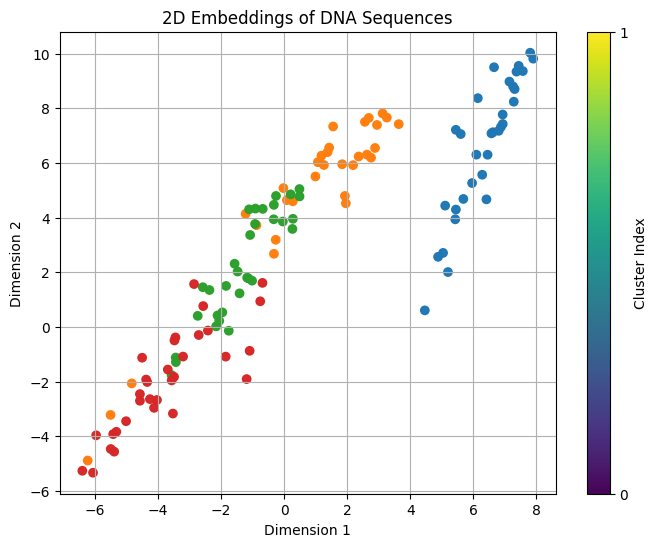

In [13]:



# Load the dataset
data_path = f"../dataset/plant_sample_{N}_seqs_{K}_clusters.tsv"
dna_sequences = []
with open(data_path, "r") as f:
    for line in f:
        seq1, seq2 = line.strip().split(",")
        dna_sequences.append(seq1+seq2)

# Define the model path
model_path = f"../models/{output_filename}.model" # f"../models/test.model" #

# Load the model
kwargs, model_state_dict = torch.load(model_path, map_location=torch.device("cpu"))
vib = VIBModel(**kwargs)
vib.load_state_dict(model_state_dict)
embedding, covs = vib.seq2emb(dna_sequences)

# Plot the 2D embeddings
import matplotlib.pyplot as plt
import matplotlib as mpl
import numpy as np

# Create a color map based on the cluster index
# colors = plt.cm.get_cmap('tab10', K)  # Get a colormap with K distinct colors
colors = mpl.colormaps['tab10'] #(np.linspace(0, 1, K))
cluster_indices = np.array([i // (N // K) for i in range(N)])  # Assuming equal distribution of sequences per cluster
point_colors = colors(cluster_indices)
plt.figure(figsize=(8, 6))
plt.scatter(embedding[:, 0], embedding[:, 1], c=point_colors, alpha=0.99)
plt.title('2D Embeddings of DNA Sequences')
plt.xlabel('Dimension 1')
plt.ylabel('Dimension 2')
plt.grid(True)
plt.colorbar(ticks=range(K), label='Cluster Index')
plt.show()

# plt.savefig("../notebooks/figures/embedding_space_hidden=64.png", dpi=300)


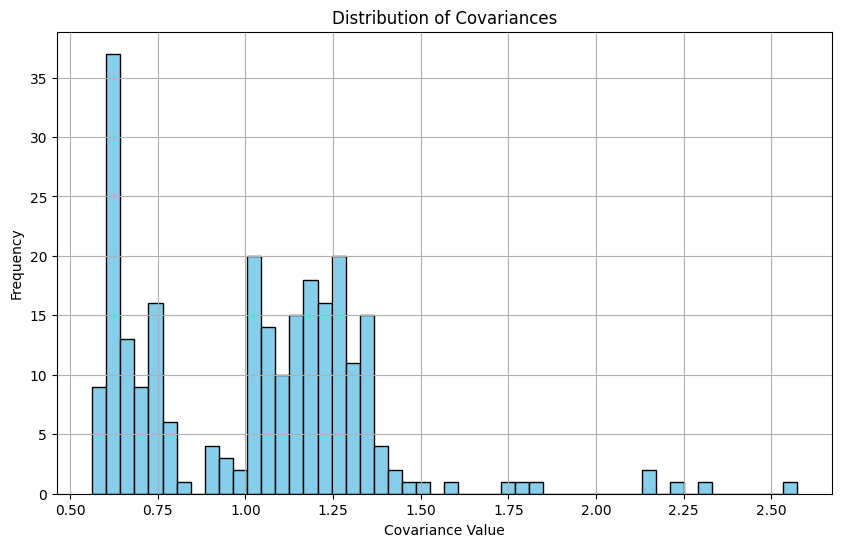

In [12]:
# Plot the distribution of covariances
# covs_np = covs.numpy()
plt.figure(figsize=(10, 6))
plt.hist(covs.flatten(), bins=50, color='skyblue', edgecolor='black')
plt.title('Distribution of Covariances')
plt.xlabel('Covariance Value')
plt.ylabel('Frequency')
plt.grid(True)
plt.show()

# plt.savefig("../notebooks/figures/cov_distribution_hidden=64.png", dpi=300)

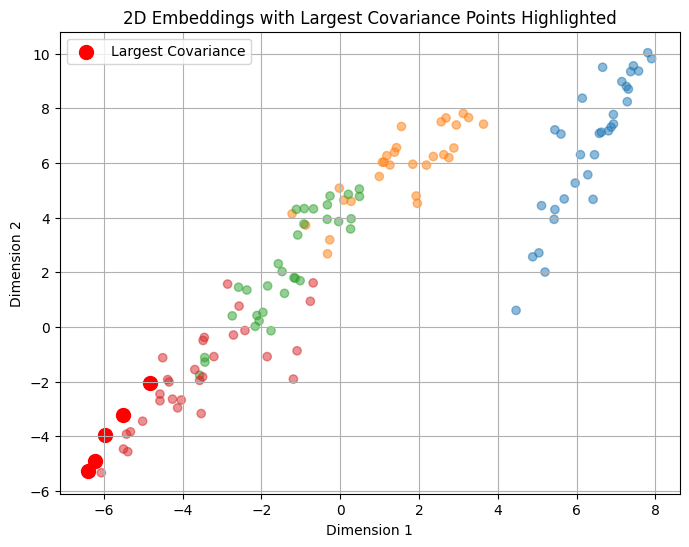

In [11]:
# Plot the embeddings and mark M embedding points having the largest covariance
M = 5
largest_cov_indices = np.argsort(np.log(covs).sum(axis=-1))[-M:]
plt.figure(figsize=(8, 6))
plt.scatter(embedding[:, 0], embedding[:, 1], c=point_colors, alpha=0.5)
plt.scatter(embedding[largest_cov_indices, 0], embedding[largest_cov_indices, 1], c='red', s=100, label='Largest Covariance')
plt.title('2D Embeddings with Largest Covariance Points Highlighted')
plt.xlabel('Dimension 1')
plt.ylabel('Dimension 2')
plt.legend()
plt.grid(True)
plt.show()

# plt.savefig("../notebooks/figures/embedding_space_with_large_covs_hidden=64.png", dpi=300)
